# 01 · Método del Gradiente
Regresión logística entrenada a mano con descenso del gradiente.

* Función objetivo: log-loss `L(w)`
* Gradiente: `∇L(w) = (1/n) · Xᵀ (p − y)`
* Actualización: `w ← w − α·∇L(w)`

In [1]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, classification_report
import time

In [2]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


## 1. Matrices (estandarizadas + intercepto)

In [3]:
scaler = StandardScaler().fit(X_train)
Xtr = np.c_[np.ones(len(X_train)), scaler.transform(X_train)]   # columna de unos = intercepto
Xte = np.c_[np.ones(len(X_test)), scaler.transform(X_test)]
ytr, yte = y_train.values.astype(float), y_test.values.astype(float)
nombres = ["intercepto"] + X_train.columns.tolist()
print("Matriz de entrenamiento:", Xtr.shape, "| coeficientes a estimar:", Xtr.shape[1])

Matriz de entrenamiento: (8101, 34) | coeficientes a estimar: 34


## 2. Algoritmo a mano

In [4]:
def sigmoide(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def funcion_objetivo(w, X, y, l1=0.0, l2=0.0):
    """Log-loss + penalidad L1/L2 (el intercepto w[0] no se penaliza)."""
    p = np.clip(sigmoide(X @ w), 1e-12, 1 - 1e-12)
    perdida = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return perdida + l1 * np.abs(w[1:]).sum() + 0.5 * l2 * (w[1:] ** 2).sum()

def gradiente(w, X, y, l1=0.0, l2=0.0):
    p = sigmoide(X @ w)
    g = X.T @ (p - y) / len(y)              # gradiente de la log-loss
    g[1:] += l2 * w[1:] + l1 * np.sign(w[1:])   # gradiente de la penalidad
    return g

def descenso_gradiente(X, y, lr=0.5, epocas=300, batch_size=None, l1=0.0, l2=0.0, semilla=SEMILLA):
    """batch_size=None -> batch; 1 -> SGD; otro valor -> mini-batch.
    Una época = recorrer todos los datos una vez."""
    rng = np.random.default_rng(semilla)
    w = np.zeros(X.shape[1])                 # 1. punto inicial
    historia = [funcion_objetivo(w, X, y, l1, l2)]
    bs = len(y) if batch_size is None else batch_size
    for epoca in range(epocas):
        idx = rng.permutation(len(y)) if bs < len(y) else np.arange(len(y))
        for inicio in range(0, len(y), bs):
            lote = idx[inicio:inicio + bs]
            w = w - lr * gradiente(w, X[lote], y[lote], l1, l2)   # 2-3. dirección -gradiente y actualización
        historia.append(funcion_objetivo(w, X, y, l1, l2))
        if bs == len(y) and abs(historia[-2] - historia[-1]) < 1e-7:   # 4. criterio de parada
            break
    return w, historia

## 3. Descenso del gradiente (batch)

Iteraciones: 3000 | tiempo: 2.1 s
Log-loss inicial: 0.6931 -> final: 0.2152
AUC en test: 0.9270


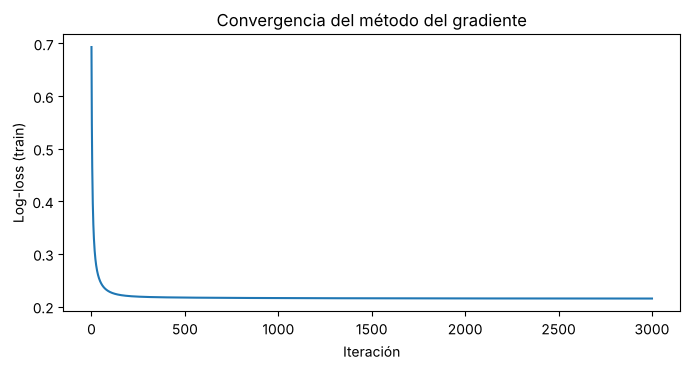

In [5]:
inicio = time.time()
w_batch, hist_batch = descenso_gradiente(Xtr, ytr, lr=0.5, epocas=3000)
print("Iteraciones: %d | tiempo: %.1f s" % (len(hist_batch) - 1, time.time() - inicio))
print("Log-loss inicial: %.4f -> final: %.4f" % (hist_batch[0], hist_batch[-1]))
print("AUC en test: %.4f" % roc_auc_score(yte, sigmoide(Xte @ w_batch)))

plt.figure(figsize=(7, 3.8)); plt.plot(hist_batch)
plt.xlabel("Iteración"); plt.ylabel("Log-loss (train)"); plt.title("Convergencia del método del gradiente")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gradiente_convergencia.png", bbox_inches="tight"); plt.show()

* La log-loss baja de 0,69 a 0,22. AUC test ≈ 0,93.

## 4. Tasa de aprendizaje (α)

α = 0.001  log-loss después de 300 iteraciones: 0.6418
α = 0.01   log-loss después de 300 iteraciones: 0.4220


α = 0.1    log-loss después de 300 iteraciones: 0.2397


α = 1.0    log-loss después de 300 iteraciones: 0.2167


α = 10.0   log-loss después de 300 iteraciones: 0.2396


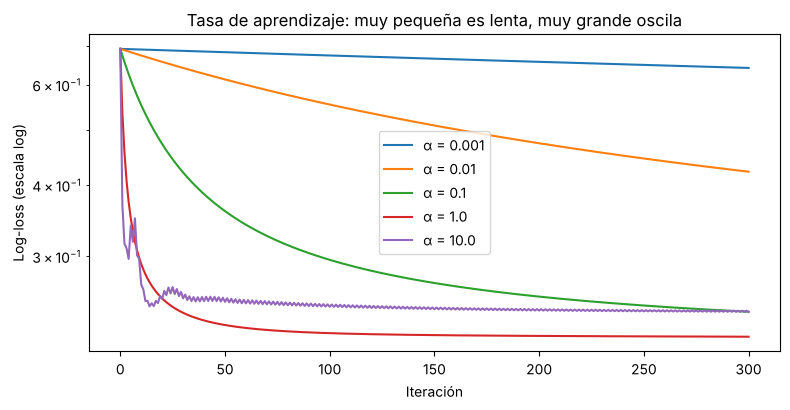

In [6]:
plt.figure(figsize=(8, 4.2))
for lr in [0.001, 0.01, 0.1, 1.0, 10.0]:
    _, h = descenso_gradiente(Xtr, ytr, lr=lr, epocas=300)
    plt.plot(h, label=f"α = {lr}")
    print(f"α = {lr:<6} log-loss después de 300 iteraciones: {h[-1]:.4f}")
plt.yscale("log"); plt.xlabel("Iteración"); plt.ylabel("Log-loss (escala log)")
plt.title("Tasa de aprendizaje: muy pequeña es lenta, muy grande oscila"); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gradiente_tasa_aprendizaje.png", bbox_inches="tight"); plt.show()

* α muy pequeño avanza lento; α muy grande salta el mínimo y termina peor.

## 5. Batch vs. mini-batch vs. SGD

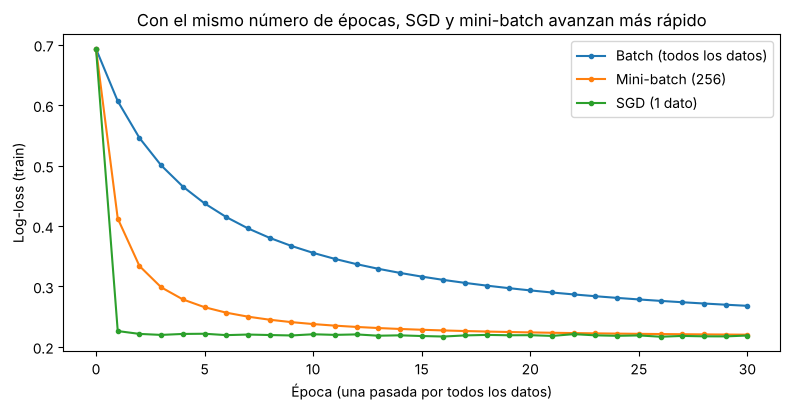

,Variante,Actualizaciones de w,Log-loss final,AUC test,Segundos
0,Batch (todos los datos),30,0.2679,0.9123,0.0299
1,Mini-batch (256),960,0.2202,0.9237,0.0611
2,SGD (1 dato),243030,0.2188,0.9269,4.0134


In [7]:
config = {"Batch (todos los datos)": dict(batch_size=None, lr=0.5),
          "Mini-batch (256)": dict(batch_size=256, lr=0.1),
          "SGD (1 dato)": dict(batch_size=1, lr=0.01)}
filas = []
plt.figure(figsize=(8, 4.2))
for nombre, c in config.items():
    inicio = time.time()
    w, h = descenso_gradiente(Xtr, ytr, epocas=30, **c)
    seg = time.time() - inicio
    actualizaciones = 30 * int(np.ceil(len(ytr) / (c["batch_size"] or len(ytr))))
    filas.append({"Variante": nombre, "Actualizaciones de w": actualizaciones, "Log-loss final": h[-1],
                  "AUC test": roc_auc_score(yte, sigmoide(Xte @ w)), "Segundos": seg})
    plt.plot(h, marker="o", ms=3, label=nombre)
plt.xlabel("Época (una pasada por todos los datos)"); plt.ylabel("Log-loss (train)")
plt.title("Con el mismo número de épocas, SGD y mini-batch avanzan más rápido"); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gradiente_batch_sgd.png", bbox_inches="tight"); plt.show()
pd.DataFrame(filas).round(4)

* Mini-batch y SGD hacen más actualizaciones por época y bajan el error más rápido.

## 6. Regularización L1 y L2

In [8]:
filas = []
for tipo in ["L2", "L1"]:
    for lam in [0.0, 0.001, 0.01, 0.05]:
        kw = {"l2": lam} if tipo == "L2" else {"l1": lam}
        w, _ = descenso_gradiente(Xtr, ytr, lr=0.5, epocas=1500, **kw)
        filas.append({"Penalidad": tipo, "λ": lam, "AUC test": roc_auc_score(yte, sigmoide(Xte @ w)),
                      "Suma |w|": np.abs(w[1:]).sum(), "Coeficientes ≈ 0": int((np.abs(w[1:]) < 0.01).sum())})
tabla_reg = pd.DataFrame(filas)
tabla_reg.round(4)

,Penalidad,λ,AUC test,Suma |w|,Coeficientes ≈ 0
0,L2,0.000,0.9267,11.6751,0
1,L2,0.001,0.9260,10.5107,0
2,L2,0.010,0.9221,7.1017,3
3,L2,0.050,0.9129,4.4379,4
4,L1,0.000,0.9267,11.6751,0
5,L1,0.001,0.9266,8.9562,6
6,L1,0.010,0.9267,4.9688,21
7,L1,0.050,0.8979,1.8412,12


* L1 (λ = 0,01) deja 21 de 33 coeficientes en cero con el mismo AUC. λ muy grande empeora.

## 7. Modelo final vs. sklearn

Métricas del modelo: Regresión logística (método del gradiente)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1638  131]
 [  63  194]]
 Accuracy        : 0.9042
 Sensibilidad    : 0.5969
 Especificidad   : 0.9630
 Precision (VPP) : 0.7549
 VPN             : 0.9259
 F1              : 0.6667
 AUC             : 0.9261
 PR-AUC          : 0.7483


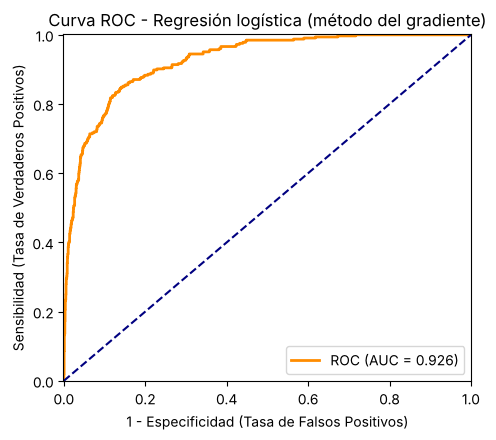

In [9]:
w_final, h_final = descenso_gradiente(Xtr, ytr, lr=0.5, epocas=3000, l2=0.001)
y_pred_prob_gd = sigmoide(Xte @ w_final)
metricas_gd = evaluar_modelo("Regresión logística (método del gradiente)", y_test, y_pred_prob_gd)

AUC test sklearn LogisticRegression: 0.9262
Correlación entre nuestros coeficientes y los de sklearn: 0.9988
AUC test sklearn SGDClassifier:      0.9209


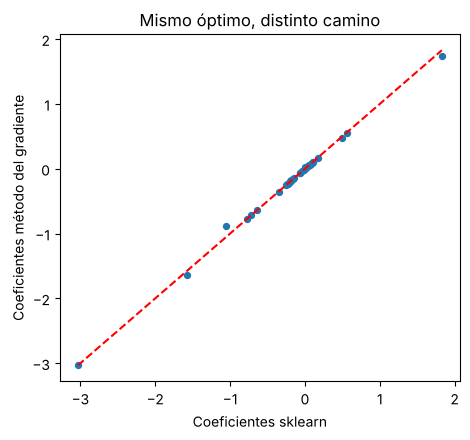

In [10]:
# ¿Llegamos al mismo resultado que sklearn? (sklearn usa otro optimizador, lbfgs)
logit_sk = LogisticRegression(C=1 / (0.001 * len(ytr)), max_iter=5000).fit(Xtr[:, 1:], ytr)
w_sk = np.r_[logit_sk.intercept_, logit_sk.coef_[0]]
print("AUC test sklearn LogisticRegression: %.4f" % roc_auc_score(yte, logit_sk.predict_proba(Xte[:, 1:])[:, 1]))
print("Correlación entre nuestros coeficientes y los de sklearn: %.4f" % np.corrcoef(w_final, w_sk)[0, 1])

sgd_sk = SGDClassifier(loss="log_loss", alpha=0.001, max_iter=50, random_state=SEMILLA).fit(Xtr[:, 1:], ytr)
print("AUC test sklearn SGDClassifier:      %.4f" % roc_auc_score(yte, sgd_sk.predict_proba(Xte[:, 1:])[:, 1]))

plt.figure(figsize=(4.8, 4.5)); plt.scatter(w_sk, w_final, s=18)
lim = [min(w_sk.min(), w_final.min()), max(w_sk.max(), w_final.max())]; plt.plot(lim, lim, "r--")
plt.xlabel("Coeficientes sklearn"); plt.ylabel("Coeficientes método del gradiente"); plt.title("Mismo óptimo, distinto camino")
plt.tight_layout(); plt.show()

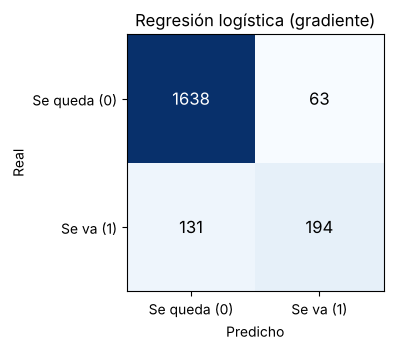

Resultados guardados en: resultados/Regresión_Logística_(Gradiente).pkl


In [11]:
plot_confusion(y_test, np.where(y_pred_prob_gd > 0.5, 1, 0), "Regresión logística (gradiente)")
guardar_resultados("Regresión Logística (Gradiente)", y_test, y_pred_prob_gd, metricas_gd,
                   {"lr": 0.5, "l2": 0.001, "iteraciones": len(h_final) - 1})

## 8. Interpretación de coeficientes

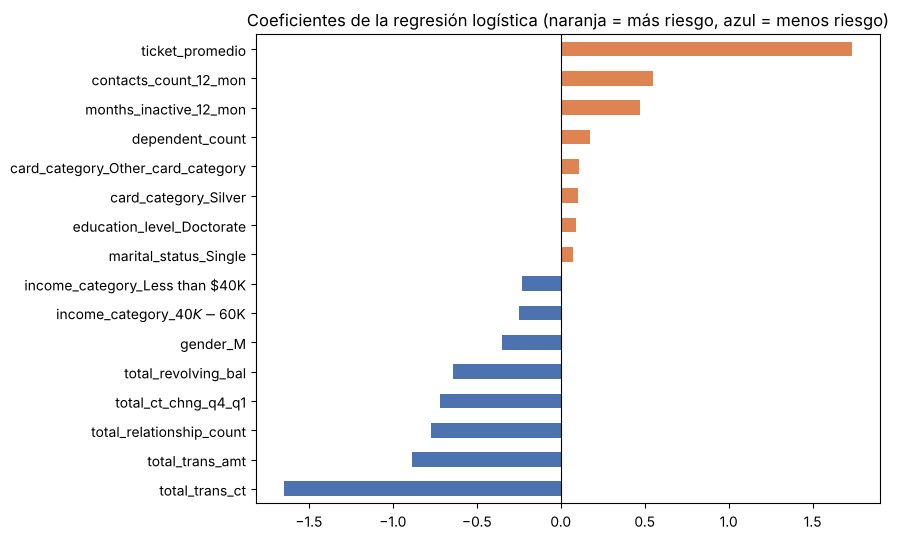

,coeficiente,razón de odds (+1 desv.)
total_trans_ct,-1.647,0.193
total_trans_amt,-0.886,0.412
total_relationship_count,-0.774,0.461
total_ct_chng_q4_q1,-0.717,0.488
total_revolving_bal,-0.640,0.528
gender_M,-0.351,0.704
income_category_$40K - $60K,-0.248,0.780
income_category_Less than $40K,-0.233,0.792
marital_status_Single,0.075,1.077
education_level_Doctorate,0.089,1.093


In [12]:
coef = pd.Series(w_final[1:], index=nombres[1:])
top = pd.concat([coef.nsmallest(8), coef.nlargest(8)]).sort_values()
plt.figure(figsize=(9, 5.5))
top.plot(kind="barh", color=np.where(top > 0, "#DD8452", "#4C72B0"))
plt.axvline(0, color="k", lw=0.8)
plt.title("Coeficientes de la regresión logística (naranja = más riesgo, azul = menos riesgo)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/gradiente_coeficientes.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"coeficiente": top, "razón de odds (+1 desv.)": np.exp(top)}).round(3)

* Transacciones, productos y saldo rotativo reducen el riesgo; contactos e inactividad lo aumentan.

## Resumen método del gradiente
* AUC test 0,926, igual a sklearn (coeficientes con correlación 0,999).
* Modelo base, lineal e interpretable.
* Queda por debajo de los modelos no lineales.